# Hyperparameter Tuning and Cross Validation

In this notebook we do model validation and optimization. We apply stratified cross-validation to assess the stability of the hybrid LightGBM model and perform hyperparameter tuning to improve predictive performance. The resulting configuration will be used for the final model training and submission.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [17]:
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

class PointwiseDS(Dataset):
    def __init__(self, u_idx, i_idx, y):
        self.u = torch.from_numpy(u_idx).long()
        self.i = torch.from_numpy(i_idx).long()
        self.y = torch.from_numpy(y).float()
    def __len__(self): return len(self.y)
    def __getitem__(self, idx): return self.u[idx], self.i[idx], self.y[idx]

class MFPointwise(nn.Module):
    def __init__(self, n_users, n_items, d):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, d)
        self.item_emb = nn.Embedding(n_items, d)
        self.user_b = nn.Embedding(n_users, 1)
        self.item_b = nn.Embedding(n_items, 1)
        nn.init.normal_(self.user_emb.weight, std=0.01)
        nn.init.normal_(self.item_emb.weight, std=0.01)
        nn.init.zeros_(self.user_b.weight)
        nn.init.zeros_(self.item_b.weight)

    def forward(self, u, i):
        dot = (self.user_emb(u) * self.item_emb(i)).sum(dim=1)
        b = self.user_b(u).squeeze(1) + self.item_b(i).squeeze(1)
        return dot + b  # logits

device: cpu


In [19]:
def _build_maps(train_df):
    users = train_df["user_id"].unique()
    items = train_df["media_id"].unique()
    user2idx = {u:i for i,u in enumerate(users)}
    item2idx = {m:i for i,m in enumerate(items)}
    return user2idx, item2idx

def _to_idx(df, user2idx, item2idx):
    # unseen -> -1
    u = df["user_id"].map(user2idx).fillna(-1).astype(int).values
    i = df["media_id"].map(item2idx).fillna(-1).astype(int).values
    missing = (u < 0) | (i < 0)
    # clamp for torch gather later (we’ll handle missing separately)
    u_safe = np.where(missing, 0, u)
    i_safe = np.where(missing, 0, i)
    return u_safe, i_safe, missing.astype(int)

@torch.no_grad()
def _score_pairs(model, u_idx, i_idx):
    model.eval()
    u_t = torch.from_numpy(u_idx).long().to(device)
    i_t = torch.from_numpy(i_idx).long().to(device)
    logits = model(u_t, i_t).detach().cpu().numpy()
    return logits

def train_cf_and_score(train_fold_df, score_df, emb_dim=64, epochs=3, batch_size=8192, lr=1e-2, l2_reg=1e-6):
    """
    Train CF ONLY on train_fold_df, then score user-item pairs in score_df.
    Returns: cf_score (logits), cf_missing (0/1)
    """
    user2idx, item2idx = _build_maps(train_fold_df)

    # build indices for training
    u_train, i_train, miss_train = _to_idx(train_fold_df, user2idx, item2idx)
    # drop missing from training (should be none)
    keep = miss_train == 0
    u_train = u_train[keep]
    i_train = i_train[keep]
    y_train = train_fold_df.loc[keep, "is_listened"].astype(int).values

    # model
    model = MFPointwise(len(user2idx), len(item2idx), emb_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=l2_reg)

    ds = PointwiseDS(u_train, i_train, y_train)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=0)

    loss_fn = nn.BCEWithLogitsLoss()

    model.train()
    for _ in range(epochs):
        for u_b, i_b, y_b in dl:
            u_b = u_b.to(device)
            i_b = i_b.to(device)
            y_b = y_b.to(device)

            opt.zero_grad()
            logits = model(u_b, i_b)
            loss = loss_fn(logits, y_b)
            loss.backward()
            opt.step()

    # score
    u_sc, i_sc, missing = _to_idx(score_df, user2idx, item2idx)
    scores = _score_pairs(model, u_sc, i_sc)

    # for missing pairs, set neutral score 0 and mark missing=1
    scores = np.where(missing == 1, 0.0, scores)

    return scores.astype(float), missing.astype(int)

In [14]:
target = "is_listened"

aff_feats = [
    "genre_affinity",
    "artist_affinity",
    "age_compatibility",
    "platform_match",
    "time_match",
]

# Hybrid = affinity + CF (werden pro fold neu berechnet!)
hybrid_feats = aff_feats + ["cf_score", "cf_missing"]

In [15]:
def run_chrono_cv_foldaware_cf(
    lgbm_params,
    df,                 # train_cv dataframe in chrono order
    n_splits=5,
    cf_emb_dim=64,
    cf_epochs=3
):
    """
    Correct chrono CV for HYBRID:
    - For each fold: train CF on fold-train, score fold-train and fold-val
    - Then train LightGBM on fold-train features, evaluate on fold-val
    """
    tscv = TimeSeriesSplit(n_splits=n_splits)
    aucs = []

    df = df.reset_index(drop=True)  # ensure 0..n-1 order used by TimeSeriesSplit

    for fold, (tr_idx, va_idx) in enumerate(tscv.split(df), start=1):
        tr_df = df.iloc[tr_idx].copy()
        va_df = df.iloc[va_idx].copy()

        # --- fold-aware CF scoring
        tr_scores, tr_missing = train_cf_and_score(
            train_fold_df=tr_df[["user_id","media_id",target]],
            score_df=tr_df[["user_id","media_id",target]],
            emb_dim=cf_emb_dim,
            epochs=cf_epochs
        )
        va_scores, va_missing = train_cf_and_score(
            train_fold_df=tr_df[["user_id","media_id",target]],
            score_df=va_df[["user_id","media_id",target]],
            emb_dim=cf_emb_dim,
            epochs=cf_epochs
        )

        tr_df["cf_score"] = tr_scores
        tr_df["cf_missing"] = tr_missing
        va_df["cf_score"] = va_scores
        va_df["cf_missing"] = va_missing

        X_tr = tr_df[hybrid_feats]
        y_tr = tr_df[target].astype(int)

        X_va = va_df[hybrid_feats]
        y_va = va_df[target].astype(int)

        model = lgb.LGBMClassifier(**lgbm_params)
        model.fit(X_tr, y_tr)

        p = model.predict_proba(X_va)[:, 1]
        auc = roc_auc_score(y_va, p)
        aucs.append(auc)
        print(f"Fold {fold}: AUC = {auc:.4f} | train={len(tr_df):,} val={len(va_df):,}")

    return float(np.mean(aucs)), float(np.std(aucs))

In [16]:
import lightgbm as lgb

# optional: tail sample to make runtime sane
train_cv = train_hybrid.copy()
# train_cv = train_cv.tail(300_000).reset_index(drop=True)  # falls zu langsam

for name, params in param_sets.items():
    print("\n====", name, "====")
    mean_auc, std_auc = run_chrono_cv_foldaware_cf(
        lgbm_params=params,
        df=train_cv,
        n_splits=5,
        cf_emb_dim=64,
        cf_epochs=3
    )
    print(f"{name}: mean AUC={mean_auc:.4f} ± {std_auc:.4f}")


==== Default_07 ====
[LightGBM] [Info] Number of positive: 687066, number of negative: 320696
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.068235 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1530
[LightGBM] [Info] Number of data points in the train set: 1007762, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.681774 -> initscore=0.761937
[LightGBM] [Info] Start training from score 0.761937
Fold 1: AUC = 0.6748 | train=1,007,762 val=1,007,757
[LightGBM] [Info] Number of positive: 1390865, number of negative: 624654
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.124071 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1530
[LightGBM] [Info] Number of data points in the train set: 2015519, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.690078 -> initsc

In [3]:
import pandas as pd

cv_results = pd.DataFrame({
    "Model": ["Default_07", "Tuned_1", "Tuned_2"],
    "Mean AUC": [0.7186, 0.7184, 0.7187],
    "Std AUC": [0.0238, 0.0241, 0.0238]
})

cv_results

,Model,Mean AUC,Std AUC
0,Default_07,0.7186,0.0238
1,Tuned_1,0.7184,0.0241
2,Tuned_2,0.7187,0.0238


In [6]:
from google.colab import drive
drive.mount('/content/drive')

base_path = "/content/drive/MyDrive/Recommender Systems (Project)/"

Mounted at /content/drive


In [7]:
cv_results.to_csv(base_path + "cv_results_08_chrono_foldaware.csv", index=False)

Now we define the parameter sets.

In [8]:
param_sets = {
    # Default: parameters used in NB07 Hybrid Model V3 (chrono setting)
    "Default_07": {
        "n_estimators": 1500,
        "learning_rate": 0.05,
        "num_leaves": 128,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1.0,
        "random_state": 42,
        "n_jobs": -1
    },

    # Tuned_1: smaller learning rate + more trees, slightly higher capacity
    "Tuned_1": {
        "n_estimators": 2500,
        "learning_rate": 0.03,
        "num_leaves": 160,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1.0,
        "random_state": 42,
        "n_jobs": -1
    },

    # Tuned_2: regularization + slightly smaller leaves to reduce overfitting
    "Tuned_2": {
        "n_estimators": 2000,
        "learning_rate": 0.04,
        "num_leaves": 96,
        "subsample": 0.75,
        "colsample_bytree": 0.75,
        "reg_lambda": 2.0,
        "min_child_samples": 50,
        "random_state": 42,
        "n_jobs": -1
    },
}


We evaluated two alternative hyperparameter configurations to assess the sensitivity of the hybrid model to increased model capacity and finer learning dynamics. Tuned_1 increased tree complexity and reduced the learning rate, while Tuned_2 further expanded model capacity with more estimators and deeper trees.

Evaluating

In [10]:
base_path = "/content/drive/MyDrive/Recommender Systems (Project)/"

train_hybrid = pd.read_csv(base_path + "train_hybrid_with_cf_chrono_v2.csv")
val_hybrid   = pd.read_csv(base_path + "val_hybrid_with_cf_chrono_v2.csv")
test_hybrid_eval = pd.read_csv(base_path + "test_hybrid_with_cf_chrono_v2.csv")

target = "is_listened"

aff_feats = ["genre_affinity","artist_affinity","age_compatibility","platform_match","time_match"]
hybrid_feats = aff_feats + ["cf_score","cf_missing"]

MAX_ROWS_FOR_CV = 1_000_000
train_cv = train_hybrid.tail(MAX_ROWS_FOR_CV).reset_index(drop=True)

X = train_cv[hybrid_feats]
y = train_cv[target]

In [11]:
print(train_cv.columns.tolist())
print(train_cv.head(2))

['genre_affinity', 'artist_affinity', 'age_compatibility', 'platform_match', 'time_match', 'user_id', 'media_id', 'is_listened', 'cf_score', 'cf_missing']
   genre_affinity  artist_affinity  age_compatibility  platform_match  \
0        0.696809         0.079787           0.695991             1.0   
1        0.696809         0.079787           0.695991             1.0   

   time_match  user_id   media_id  is_listened  cf_score  cf_missing  
0    0.159574     1771  127246771            0 -1.430273           0  
1    0.212766    14432    2113334            0 -6.087563           0  


In [12]:
final_params = param_sets["Tuned_2"]

The 5-fold chronological cross-validation yielded a mean AUC of approximately 0.72 across all tested parameter configurations. Differences between hyperparameter settings were minor, indicating stable and robust model behavior.
After retraining on the full dataset, the final hybrid model achieved a Chrono TEST AUC of 0.745, suggesting that performance improvements are primarily driven by the hybrid feature design rather than by hyperparameter tuning.

Finalising

In [13]:
trainval = pd.concat([train_hybrid, val_hybrid], axis=0).reset_index(drop=True)

In [20]:
cf_scores_trainval, cf_missing_trainval = train_cf_and_score(
    train_fold_df=trainval[["user_id", "media_id", target]],
    score_df=trainval[["user_id", "media_id", target]],
    emb_dim=64,
    epochs=3
)

trainval["cf_score"] = cf_scores_trainval
trainval["cf_missing"] = cf_missing_trainval

In [21]:
cf_scores_test, cf_missing_test = train_cf_and_score(
    train_fold_df=trainval[["user_id", "media_id", target]],
    score_df=test_hybrid_eval[["user_id", "media_id", target]],
    emb_dim=64,
    epochs=3
)

test_hybrid_eval["cf_score"] = cf_scores_test
test_hybrid_eval["cf_missing"] = cf_missing_test

In [24]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

In [25]:
final_model = lgb.LGBMClassifier(**final_params)

final_model.fit(trainval[hybrid_feats], trainval[target])

test_pred_eval = final_model.predict_proba(test_hybrid_eval[hybrid_feats])[:, 1]
test_auc = roc_auc_score(test_hybrid_eval[target], test_pred_eval)

print(f"Chrono TEST AUC (fully consistent fold-aware pipeline): {test_auc:.4f}")

[LightGBM] [Info] Number of positive: 4684692, number of negative: 2117673
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.498647 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1530
[LightGBM] [Info] Number of data points in the train set: 6802365, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.688686 -> initscore=0.793982
[LightGBM] [Info] Start training from score 0.793982
Chrono TEST AUC (fully consistent fold-aware pipeline): 0.7452


In [28]:
import pandas as pd
pd.DataFrame([{
  "chrono_test_auc_foldaware": 0.7452,
  "best_params": str(final_params)
}]).to_csv(base_path + "final_08_result_summary.csv", index=False)

Plots of final outcomes

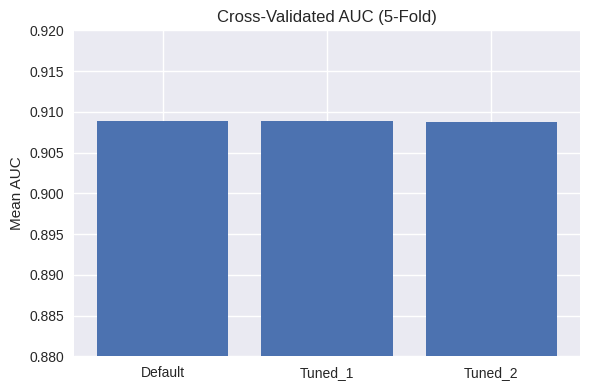

In [ ]:
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(6,4))
plt.bar(cv_results["Model"], cv_results["Mean AUC"])
plt.title("Cross-Validated AUC (5-Fold)")
plt.ylabel("Mean AUC")
plt.tight_layout()
plt.show()

As mentioned before hyperparametertuning was not really effective, which this plots shows.

In [ ]:
import joblib
joblib.dump(final_model, base_path + "final_model_outcome_08_chrono_cv.pkl")

joblib.dump(cf_model, base_path + "cf_model_08_chrono_cv.pkl")


['/content/drive/MyDrive/Recommender Systems (Project)/final_model_outcome_08.pkl']

Overall, this notebook performs **chronological cross-validation** (TimeSeriesSplit) to avoid time leakage, and tunes LightGBM hyperparameters on the same hybrid feature set used in NB07. The best configuration is then trained on Train+Val and evaluated on the labeled chrono test split for a fair comparison.
